## Introduction to OCEL

In [1]:
import networkx as nx
import pandas as pd
import pm4py

In [2]:
event_log_path = 'C:/Users/Pavel/Desktop/PhD/OCEL/event_logs/order_management.xml'
# event_log_path = 'C:/Users/Pavel/Desktop/PhD/OCEL/event_logs/p2p.xml'
# event_log_path = 'C:/Users/Pavel/Desktop/PhD/OCEL/event_logs/container_logistics.xml'

ocel = pm4py.read_ocel2(event_log_path)

events_df = ocel.events
objects_df = ocel.objects
relations_df = ocel.relations

c:\Users\Pavel\Desktop\PhD\OCEL\.venv\lib\site-packages\pm4py\util\dt_parsing\parser.py:82: UserWarning: ISO8601 strings are not fully supported with strpfromiso for Python versions below 3.11
  warnings.warn(


In [3]:
print(objects_df['ocel:type'].unique())

objects_df.head()

['orders' 'items' 'packages' 'customers' 'products' 'employees']


,ocel:oid,ocel:type,price,weight,role
0,o-990001,orders,1353.98,NaN,NaN
1,o-990002,orders,3083.00,NaN,NaN
2,o-990003,orders,3599.99,NaN,NaN
3,o-990004,orders,2241.95,NaN,NaN
4,o-990005,orders,3049.98,NaN,NaN


In [4]:
events_df.head()

,ocel:eid,ocel:activity,ocel:timestamp
3128,place_o-990001,place order,2023-04-03 10:08:18+00:00
9800,pick_i-880003,pick item,2023-04-03 11:21:49+00:00
3129,place_o-990002,place order,2023-04-03 14:36:55+00:00
3130,place_o-990003,place order,2023-04-03 21:31:23+00:00
9801,pick_i-880001,pick item,2023-04-04 07:50:21+00:00


In [5]:
relations_df[relations_df['ocel:oid'] == 'o-990001']

,ocel:eid,ocel:activity,ocel:timestamp,ocel:oid,ocel:type,ocel:qualifier
32978,place_o-990001,place order,2023-04-03 10:08:18+00:00,o-990001,orders,order
67960,confirm_o-990001,confirm order,2023-04-04 14:34:29+00:00,o-990001,orders,order
16,pay_o-990001,pay order,2023-04-05 15:47:04+00:00,o-990001,orders,order


In [6]:
# Create a heterogeneous graph with "event" and "object" nodes
G = nx.Graph()

# Add event nodes
for _, row in events_df.iterrows():
    attributes = {k: str(v) for k, v in row.dropna().to_dict().items()}
    attributes['node_type'] = 'event'

    G.add_node(row['ocel:eid'], **attributes)

# Add object nodes
for _, row in objects_df.iterrows():
    attributes = {k: str(v) for k, v in row.dropna().to_dict().items()}
    attributes['node_type'] = 'object'

    G.add_node(row['ocel:oid'], **attributes)

# Add edges representing the relations (Event <-> Object)
for _, row in relations_df.iterrows():
    G.add_edge(row['ocel:eid'], row['ocel:oid'])

print(
    f'\nGraph created with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.'
)


Graph created with 31848 nodes and 147385 edges.


### Graph Perspective Definition

Not only can we consider events and objects as different node types in a graph, but we can also consider different object types as different node types.

In [7]:
# orders, customers, items, employees, packages, products
lead_object_type = 'orders'

In [8]:
events_per_order_counts = (
    objects_df[objects_df['ocel:type'] == lead_object_type]
    .merge(relations_df[['ocel:oid', 'ocel:eid']], on='ocel:oid', how='left')
    .groupby('ocel:oid', as_index=False)
    .size()
    .rename(columns={'size': 'num_events'})
    .sort_values('num_events', ascending=True)
    .reset_index(drop=True)
)

events_per_order_counts.tail()

,ocel:oid,num_events
1995,o-991986,6
1996,o-991196,6
1997,o-990679,7
1998,o-991443,7
1999,o-990720,7


### Ego Network Visualization

In [9]:
example_ocel_id = 'o-990720'

target_exists = (
    (objects_df['ocel:type'] == lead_object_type)
    & (objects_df['ocel:oid'] == example_ocel_id)
).any()

if not target_exists:
    raise ValueError(
        f'Object {example_ocel_id} was not found for object type {lead_object_type}.'
    )

# Build the ego-graph around the target object
# n-hop neighbors (or k parameter in graph literature):
# 0 = the target object itself
# 1 = the events directly related to the target object
# 2 = the objects directly related to the target object
# 3 = the events directly related to the objects from step 2
# 4 = the objects directly related to the events from step 3
ego_nodes = nx.ego_graph(G, example_ocel_id, radius=2).nodes()
ego_G = G.subgraph(ego_nodes).copy()


In [10]:
import seaborn as sns
from matplotlib import colors as mcolors


object_types = objects_df['ocel:type'].dropna().unique()
type_to_color = {
    obj_type: mcolors.to_hex(color)
    for obj_type, color in zip(
        object_types, sns.color_palette('husl', len(object_types)), strict=False
    )
}

In [11]:
type_to_color

{'orders': '#f77189',
 'items': '#bb9832',
 'packages': '#50b131',
 'customers': '#36ada4',
 'products': '#3ba3ec',
 'employees': '#e866f4'}

#### Matplotlib

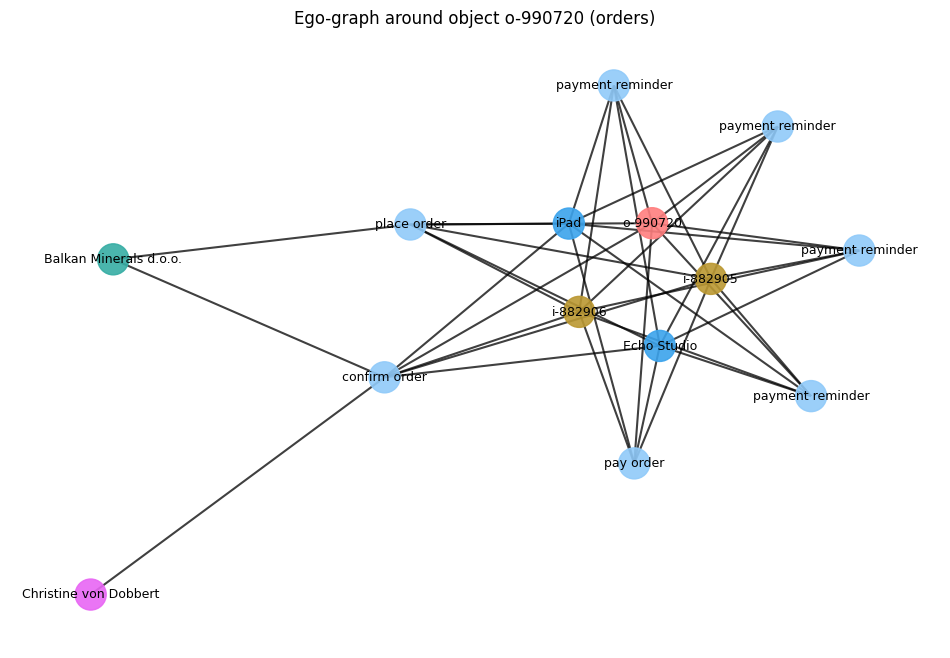

In [12]:
import matplotlib.pyplot as plt


node_colors = []
for node in ego_G.nodes():
    node_info = ego_G.nodes[node]

    if node_info.get('node_type') == 'event':
        node_colors.append('#90caf9')  # event nodes: blue
    elif node == example_ocel_id:
        node_colors.append('#ff7f7f')  # target object: red
    else:
        obj_type = node_info.get('obj_class') or node_info.get('ocel:type')
        node_colors.append(type_to_color.get(obj_type, '#a5d6a7'))

pos = nx.spring_layout(ego_G, seed=42)

custom_labels = {}
for node, node_info in ego_G.nodes(data=True):
    custom_labels[node] = (
        node_info.get('ocel:activity')
        if node_info.get('node_type') == 'event'
        else str(node)
    )

plt.figure(figsize=(12, 8))
nx.draw_networkx_nodes(
    ego_G,
    pos,
    node_color=node_colors,
    node_size=500,
    alpha=0.9,
)
nx.draw_networkx_edges(
    ego_G,
    pos,
    width=1.5,
    alpha=0.75,
)
nx.draw_networkx_labels(
    ego_G,
    pos,
    labels=custom_labels,
    font_size=9,
)

plt.title(f'Ego-graph around object {example_ocel_id} ({lead_object_type})')
plt.axis('off')
plt.show()


#### PyVis

In [13]:
import os
import webbrowser

from pyvis.network import Network


net = Network(
    height='800px',
    width='100%',
    bgcolor='#ffffff',
    font_color='black',
    notebook=True,
    cdn_resources='in_line',
)

for node in ego_G.nodes():
    node_info = ego_G.nodes[node]

    if node_info.get('node_type') == 'event':
        color = '#90caf9'
    elif node == example_ocel_id:
        color = '#ff7f7f'
    else:
        obj_type = node_info.get('obj_class') or node_info.get('ocel:type')
        color = type_to_color.get(obj_type, '#a5d6a7')

    ego_G.nodes[node]['color'] = color
    ego_G.nodes[node]['label'] = (
        node_info.get('ocel:activity')
        if node_info.get('node_type') == 'event'
        else str(node)
    )

    ego_G.nodes[node]['title'] = f'Type: {node_info.get("node_type", "unknown")}'
    ego_G.nodes[node]['title'] = f'Type: {node_info.get("node_type", "unknown")}'

    hover_text = f'ID: {node}\n'
    hover_text += '—' * 20 + '\n'
    for key, value in node_info.items():
        if key not in ['color', 'label', 'size', 'title', 'hover', 'node_type']:
            hover_text += f'{key}: {value}\n'

    ego_G.nodes[node]['title'] = hover_text

net.from_nx(ego_G)

html_content = net.generate_html()
output_file_path = 'outputs/order_management.html'

os.makedirs(os.path.dirname(output_file_path), exist_ok=True)
with open(output_file_path, 'w', encoding='utf-8') as f:
    f.write(html_content)

webbrowser.open(f'file://{os.path.abspath(output_file_path)}')

True

#### Gravis

In [ ]:
import gravis as gv


for node in ego_G.nodes():
    node_info = ego_G.nodes[node]

    if node_info.get('node_type') == 'event':
        ego_G.nodes[node]['color'] = '#90caf9'
    elif node == example_ocel_id:
        ego_G.nodes[node]['color'] = '#ff7f7f'
        ego_G.nodes[node]['size'] = 20
    else:
        obj_type = node_info.get('obj_class') or node_info.get('ocel:type')
        ego_G.nodes[node]['color'] = type_to_color.get(obj_type, '#a5d6a7')

    hover_html = "<div style='font-family: Arial; font-size: 12px;'>"
    hover_html += f'<b>ID:</b> {node}<br>'
    hover_html += "<hr style='margin: 4px 0;'>"

    ego_G.nodes[node]['label'] = (
        node_info.get('ocel:activity')
        if node_info.get('node_type') == 'event'
        else str(node)
    )

    for key, value in node_info.items():
        if key not in ['color', 'label', 'size', 'title', 'hover', 'node_type']:
            hover_html += f'<b>{key}:</b> {value}<br>'

    hover_html += '</div>'

    ego_G.nodes[node]['hover'] = hover_html

fig = gv.three(ego_G, graph_height=800, node_label_data_source='label')
fig.display()

## Temporal Split

In [ ]:
drop_longest_percentile = 0.95
test_ratio = 0.3

events_df['ocel:timestamp'] = pd.to_datetime(events_df['ocel:timestamp'], utc=True)

# 1. Map events to the Lead Object Type
lead_objects = objects_df[objects_df['ocel:type'] == lead_object_type]['ocel:oid']

lead_relations = relations_df[relations_df['ocel:oid'].isin(lead_objects)]

# Join with events to get timestamps for these specific relations
lead_events = lead_relations[['ocel:eid', 'ocel:oid']].merge(
    events_df[['ocel:eid', 'ocel:timestamp']], on='ocel:eid', how='left'
)

# Calculate start and end times for each Lead Object
lifecycles = lead_events.groupby('ocel:oid')['ocel:timestamp'].agg(['min', 'max'])
lifecycles['duration'] = (lifecycles['max'] - lifecycles['min']).dt.total_seconds()

# 2. Filter Longest Cases
max_duration_threshold = lifecycles['duration'].quantile(drop_longest_percentile)
valid_lifecycles = lifecycles[lifecycles['duration'] <= max_duration_threshold].copy()

# 3. Determine Temporal Separation Point
starts_sorted = valid_lifecycles['min'].sort_values()
split_idx = int(len(starts_sorted) * (1 - test_ratio))
separation_time = starts_sorted.iloc[split_idx]

# 4. Assign Objects (Strict Splitting)
train_lead_oids = valid_lifecycles[
    valid_lifecycles['max'] < separation_time
].index.tolist()
test_lead_oids = valid_lifecycles[
    valid_lifecycles['max'] >= separation_time
].index.tolist()

# 5. Mask Event Pools
# Only events that happened before the separation time
train_event_pool = events_df[events_df['ocel:timestamp'] < separation_time].copy()

# All the events since
test_event_pool = events_df.copy()

# 6. Calculate Debiasing Cutoffs for the Test Set
latest_timestamp = events_df['ocel:timestamp'].max()
test_debias_cutoff = latest_timestamp - pd.Timedelta(seconds=max_duration_threshold)

split_metadata = {
    'lead_object_type': lead_object_type,
    'separation_time': separation_time,
    'test_debias_cutoff': test_debias_cutoff,
    'max_duration_seconds': max_duration_threshold,
}

In [16]:
len(train_event_pool)
len(test_event_pool)

21008